# Single-Target Chest X-Ray Disease Classification with PyTorch

This notebook trains **one independent DenseNet121 model per pathology** instead of a single 14-output multi-label model.

It keeps the main experimental choices from the supplied multi-label notebook:

- the same NIH train/validation/test CSV files;
- patient-level leakage prevention;
- the same sample-wise normalization;
- ImageNet-pretrained DenseNet121;
- unweighted `BCEWithLogitsLoss`;
- Adam with learning rate `1e-4`;
- at most **10 epochs per target**.

For each pathology, the notebook keeps the checkpoint with the **best validation PR-AUC** and then tunes that pathology's classification threshold on the validation set by maximizing F1. The untouched test set is evaluated only after all validation-based choices are fixed.

In [2]:
import copy
import gc
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
)

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import densenet121, DenseNet121_Weights

In [3]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Load the data

In [4]:
train_df = pd.read_csv("data/nih/train-small.csv")
valid_df = pd.read_csv("data/nih/valid-small.csv")
test_df = pd.read_csv("data/nih/test.csv")

print("Initial train size:", len(train_df))
print("Initial valid size:", len(valid_df))
print("Test size:", len(test_df))

Initial train size: 1000
Initial valid size: 200
Test size: 420


In [5]:
disease_names = [
    "Cardiomegaly",
    "Emphysema",
    "Effusion",
    "Hernia",
    "Infiltration",
    "Mass",
    "Nodule",
    "Atelectasis",
    "Pneumothorax",
    "Pleural_Thickening",
    "Pneumonia",
    "Fibrosis",
    "Edema",
    "Consolidation",
]

print("Number of pathologies:", len(disease_names))

Number of pathologies: 14


## 2. Recreate a patient-disjoint train/validation split

The original notebook detected overlap between the supplied train and validation files. We therefore merge only those two files and split **unique patients**, preserving approximately the original validation proportion. The test set remains untouched.

In [6]:
def has_patient_leakage(df1, df2, patient_col="PatientId"):
    return len(set(df1[patient_col]).intersection(set(df2[patient_col]))) > 0

print("Before re-splitting:")
print("Train / valid leakage:", has_patient_leakage(train_df, valid_df))
print("Train / test leakage :", has_patient_leakage(train_df, test_df))
print("Valid / test leakage :", has_patient_leakage(valid_df, test_df))

Before re-splitting:
Train / valid leakage: True
Train / test leakage : False
Valid / test leakage : False


In [7]:
valid_ratio = len(valid_df) / (len(train_df) + len(valid_df))

train_valid_df = pd.concat([train_df, valid_df], ignore_index=True)
patients = train_valid_df["PatientId"].unique()

train_patients, valid_patients = train_test_split(
    patients,
    test_size=valid_ratio,
    random_state=SEED,
)

train_df = train_valid_df[
    train_valid_df["PatientId"].isin(train_patients)
].reset_index(drop=True)

valid_df = train_valid_df[
    train_valid_df["PatientId"].isin(valid_patients)
].reset_index(drop=True)

print(f"Original validation ratio: {valid_ratio:.3f}")
print("New train size:", len(train_df))
print("New valid size:", len(valid_df))

print("After re-splitting:")
print("Train / valid leakage:", has_patient_leakage(train_df, valid_df))
print("Train / test leakage :", has_patient_leakage(train_df, test_df))
print("Valid / test leakage :", has_patient_leakage(valid_df, test_df))

assert not has_patient_leakage(train_df, valid_df)
assert not has_patient_leakage(train_df, test_df)
assert not has_patient_leakage(valid_df, test_df)

Original validation ratio: 0.167
New train size: 1009
New valid size: 191
After re-splitting:
Train / valid leakage: False
Train / test leakage : False
Valid / test leakage : False


## 3. Dataset and preprocessing

The preprocessing matches the supplied multi-label notebook. Each image is resized to 320 × 320, converted to a tensor, and normalized using its own mean and standard deviation.

In [8]:
class SamplewiseNormalize:
    def __call__(self, image):
        mean = image.mean()
        std = image.std()
        return (image - mean) / (std + 1e-8)


common_transform = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.ToTensor(),
    SamplewiseNormalize(),
])

In [9]:
class SingleTargetChestXrayDataset(Dataset):
    def __init__(self, df, image_dir, x_col, target_col, transform=None):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.x_col = x_col
        self.target_col = target_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / row[self.x_col]
        image = Image.open(image_path).convert("RGB")

        target = torch.tensor(
            float(row[self.target_col]),
            dtype=torch.float32,
        )

        if self.transform is not None:
            image = self.transform(image)

        return image, target

In [10]:
IMAGE_DIR = "data/nih/images-small/"
BATCH_SIZE = 8
NUM_EPOCHS = 10
PATIENCE = 2
LEARNING_RATE = 1e-4

CHECKPOINT_DIR = Path("single_target_checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Maximum epochs per target:", NUM_EPOCHS)
print("Checkpoint directory:", CHECKPOINT_DIR.resolve())

Maximum epochs per target: 10
Checkpoint directory: C:\Users\Mahugnon\Documents\Medical Imaging\Chest X-Ray Medical Diagnosis with Deep Learning\single_target_checkpoints


## 4. Inspect target prevalence

Because each pathology is trained independently, it is useful to inspect how many positive and negative examples are available for each target in train, validation, and test.

In [11]:
prevalence_rows = []

for disease in disease_names:
    prevalence_rows.append({
        "Disease": disease,
        "Train_Pos": int(train_df[disease].sum()),
        "Train_Neg": int(len(train_df) - train_df[disease].sum()),
        "Valid_Pos": int(valid_df[disease].sum()),
        "Valid_Neg": int(len(valid_df) - valid_df[disease].sum()),
        "Test_Pos": int(test_df[disease].sum()),
        "Test_Neg": int(len(test_df) - test_df[disease].sum()),
    })

prevalence_df = pd.DataFrame(prevalence_rows)
prevalence_df

,Disease,Train_Pos,Train_Neg,Valid_Pos,Valid_Neg,Test_Pos,Test_Neg
0,Cardiomegaly,23,986,1,190,50,370
1,Emphysema,15,994,1,190,56,364
2,Effusion,134,875,21,170,53,367
3,Hernia,2,1007,1,190,50,370
4,Infiltration,174,835,30,161,59,361
5,Mass,46,963,8,183,60,360
6,Nodule,52,957,13,178,54,366
7,Atelectasis,111,898,14,177,60,360
8,Pneumothorax,41,968,7,184,55,365
9,Pleural_Thickening,23,986,4,187,58,362


## 5. Model, loaders, and evaluation helpers

Each target gets a fresh ImageNet-pretrained DenseNet121 with a **single output logit**. A fresh training loader is also created with the same random seed for every target so that the shuffle process is reproducible.

In [12]:
def make_loaders_for_target(target_name, seed=SEED):
    train_dataset = SingleTargetChestXrayDataset(
        train_df, IMAGE_DIR, "Image", target_name, common_transform
    )
    valid_dataset = SingleTargetChestXrayDataset(
        valid_df, IMAGE_DIR, "Image", target_name, common_transform
    )
    test_dataset = SingleTargetChestXrayDataset(
        test_df, IMAGE_DIR, "Image", target_name, common_transform
    )

    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, valid_loader, test_loader

In [13]:
def build_single_target_model(seed=SEED):
    # Reset the seed before replacing the classifier so each target starts
    # from the same pretrained backbone and reproducible head initialization.
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = densenet121(weights=DenseNet121_Weights.DEFAULT)
    model.classifier = nn.Linear(
        model.classifier.in_features,
        1,
    )

    return model.to(device)

In [14]:
def get_binary_predictions(model, loader, device):
    model.eval()

    all_targets = []
    all_probs = []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device)

            logits = model(images).squeeze(1)
            probs = torch.sigmoid(logits)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(targets.numpy())

    y_true = np.concatenate(all_targets, axis=0)
    y_prob = np.concatenate(all_probs, axis=0)

    return y_true, y_prob

In [15]:
def binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)

    n_pos = int(y_true.sum())
    n_neg = int(len(y_true) - n_pos)

    roc_auc = (
        roc_auc_score(y_true, y_prob)
        if np.unique(y_true).size == 2
        else np.nan
    )

    pr_auc = (
        average_precision_score(y_true, y_prob)
        if n_pos > 0
        else np.nan
    )

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    f1 = f1_score(y_true, y_pred, zero_division=0)

    return {
        "N_Pos": n_pos,
        "N_Neg": n_neg,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "F1": f1,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
    }

In [16]:
def find_best_threshold_f1(
    y_true,
    y_prob,
    thresholds=np.arange(0.01, 1.00, 0.01),
):
    # If validation has no positive examples, threshold tuning is not meaningful.
    if np.sum(y_true) == 0:
        return 0.5, np.nan

    best_threshold = 0.5
    best_f1 = -1.0

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)
        score = f1_score(y_true, y_pred, zero_division=0)

        if score > best_f1:
            best_f1 = score
            best_threshold = float(threshold)

    return best_threshold, best_f1

## 6. Train one independent model for each pathology

**Model-selection rule:** keep the epoch with the highest validation PR-AUC. PR-AUC is particularly informative here because the positive class is rare for many pathologies.

If a validation target contains no positive examples, PR-AUC is undefined; in that exceptional case the code falls back to the lowest validation loss.

In [17]:
def train_one_target(target_name):
    print("=" * 80)
    print(f"TARGET: {target_name}")
    print("=" * 80)

    train_loader, valid_loader, _ = make_loaders_for_target(
        target_name,
        seed=SEED,
    )

    model = build_single_target_model(seed=SEED)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    history = {
        "train_loss": [],
        "valid_loss": [],
        "valid_pr_auc": [],
    }

    best_state = None
    best_epoch = None
    best_pr_auc = -np.inf
    best_valid_loss = np.inf
    selection_used = None
    epochs_without_improvement = 0

    for epoch in range(NUM_EPOCHS):
        model.train()
        running_loss = 0.0

        for images, targets in train_loader:
            images = images.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            logits = model(images).squeeze(1)
            loss = criterion(logits, targets)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        # Validation loss + predictions
        model.eval()
        valid_running_loss = 0.0
        valid_targets = []
        valid_probs = []

        with torch.no_grad():
            for images, targets in valid_loader:
                images = images.to(device)
                targets_device = targets.to(device)

                logits = model(images).squeeze(1)
                loss = criterion(logits, targets_device)
                probs = torch.sigmoid(logits)

                valid_running_loss += loss.item()
                valid_targets.append(targets.numpy())
                valid_probs.append(probs.cpu().numpy())

        valid_loss = valid_running_loss / len(valid_loader)
        y_valid = np.concatenate(valid_targets)
        p_valid = np.concatenate(valid_probs)

        if np.sum(y_valid) > 0 and np.unique(y_valid).size == 2:
            valid_pr_auc = average_precision_score(y_valid, p_valid)
        else:
            valid_pr_auc = np.nan

        history["train_loss"].append(train_loss)
        history["valid_loss"].append(valid_loss)
        history["valid_pr_auc"].append(valid_pr_auc)

        print(
            f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} "
            f"- Train Loss: {train_loss:.4f} "
            f"- Valid Loss: {valid_loss:.4f} "
            f"- Valid PR-AUC: {valid_pr_auc:.4f}"
            if np.isfinite(valid_pr_auc)
            else
            f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} "
            f"- Train Loss: {train_loss:.4f} "
            f"- Valid Loss: {valid_loss:.4f} "
            f"- Valid PR-AUC: NaN"
        )

        # Prefer PR-AUC when it is defined.
        if np.isfinite(valid_pr_auc):
            improved = valid_pr_auc > best_pr_auc
            if improved:
                best_pr_auc = valid_pr_auc
                selection_used = "PR_AUC"
        else:
            improved = valid_loss < best_valid_loss
            if improved:
                best_valid_loss = valid_loss
                selection_used = "Valid_Loss"

        if improved:
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch + 1}. "
                f"Best epoch: {best_epoch}"
            )
            break

    if best_state is None:
        raise RuntimeError(f"No checkpoint selected for {target_name}")

    model.load_state_dict(best_state)

    y_valid, p_valid = get_binary_predictions(
        model,
        valid_loader,
        device,
    )

    best_threshold, best_f1 = find_best_threshold_f1(
        y_valid,
        p_valid,
    )

    valid_metrics = binary_metrics(
        y_valid,
        p_valid,
        threshold=best_threshold,
    )

    checkpoint_path = CHECKPOINT_DIR / f"densenet121_{target_name}.pth"

    checkpoint = {
        "target_name": target_name,
        "model_name": "DenseNet121",
        "pretrained": True,
        "loss": "BCEWithLogitsLoss_unweighted",
        "model_state_dict": model.state_dict(),
        "best_epoch": best_epoch,
        "selection_metric": selection_used,
        "validation_threshold": best_threshold,
        "validation_metrics": valid_metrics,
        "seed": SEED,
        "max_epochs": NUM_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "image_size": 320,
        "normalization": "sample-wise",
    }

    torch.save(checkpoint, checkpoint_path)

    row = {
        "Disease": target_name,
        "Best_Epoch": best_epoch,
        "Selection_Metric": selection_used,
        "Threshold": best_threshold,
        **valid_metrics,
        "Checkpoint": str(checkpoint_path),
    }

    print()
    print(f"Selected epoch: {best_epoch}")
    print(f"Validation threshold: {best_threshold:.2f}")
    print(f"Validation PR-AUC: {valid_metrics['PR_AUC']:.4f}")
    print(f"Saved: {checkpoint_path}")
    print()

    # Free GPU memory before the next disease.
    del model, optimizer, train_loader, valid_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return row, history

In [34]:
validation_rows = []
training_histories = {}

for disease in disease_names:
    row, history = train_one_target(disease)
    validation_rows.append(row)
    training_histories[disease] = history

validation_results = pd.DataFrame(validation_rows)
validation_results

TARGET: Cardiomegaly
Epoch 01/10 - Train Loss: 0.1716 - Valid Loss: 0.0543 - Valid PR-AUC: 0.0100
Epoch 02/10 - Train Loss: 0.0613 - Valid Loss: 0.0518 - Valid PR-AUC: 0.0115
Epoch 03/10 - Train Loss: 0.0276 - Valid Loss: 0.0497 - Valid PR-AUC: 0.0100
Epoch 04/10 - Train Loss: 0.0108 - Valid Loss: 0.0379 - Valid PR-AUC: 0.0083
Early stopping at epoch 4. Best epoch: 2

Selected epoch: 2
Validation threshold: 0.02
Validation PR-AUC: 0.0115
Saved: single_target_checkpoints\densenet121_Cardiomegaly.pth

TARGET: Emphysema
Epoch 01/10 - Train Loss: 0.1511 - Valid Loss: 0.0463 - Valid PR-AUC: 0.0182
Epoch 02/10 - Train Loss: 0.0422 - Valid Loss: 0.0484 - Valid PR-AUC: 0.0116
Epoch 03/10 - Train Loss: 0.0161 - Valid Loss: 0.0396 - Valid PR-AUC: 0.0204
Epoch 04/10 - Train Loss: 0.0068 - Valid Loss: 0.0333 - Valid PR-AUC: 0.0323
Epoch 05/10 - Train Loss: 0.0039 - Valid Loss: 0.0339 - Valid PR-AUC: 0.0217
Epoch 06/10 - Train Loss: 0.0024 - Valid Loss: 0.0341 - Valid PR-AUC: 0.0400
Epoch 07/10 - T

,Disease,Best_Epoch,Selection_Metric,Threshold,N_Pos,N_Neg,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity,Checkpoint
0,Cardiomegaly,2,PR_AUC,0.02,1,190,0.547368,0.011494,0.017544,1.000000,0.410526,single_target_checkpoints\densenet121_Cardiome...
1,Emphysema,8,PR_AUC,0.01,1,190,0.915789,0.058824,0.000000,0.000000,0.994737,single_target_checkpoints\densenet121_Emphysem...
2,Effusion,3,PR_AUC,0.08,21,170,0.837815,0.415398,0.539683,0.809524,0.852941,single_target_checkpoints\densenet121_Effusion...
3,Hernia,5,PR_AUC,0.01,1,190,0.894737,0.047619,0.000000,0.000000,0.989474,single_target_checkpoints\densenet121_Hernia.pth
4,Infiltration,2,PR_AUC,0.13,30,161,0.710766,0.408400,0.438356,0.533333,0.832298,single_target_checkpoints\densenet121_Infiltra...
5,Mass,1,PR_AUC,0.11,8,183,0.776639,0.157409,0.285714,0.250000,0.978142,single_target_checkpoints\densenet121_Mass.pth
6,Nodule,2,PR_AUC,0.10,13,178,0.563094,0.127323,0.235294,0.307692,0.904494,single_target_checkpoints\densenet121_Nodule.pth
7,Atelectasis,3,PR_AUC,0.05,14,177,0.707022,0.132454,0.253165,0.714286,0.689266,single_target_checkpoints\densenet121_Atelecta...
8,Pneumothorax,5,PR_AUC,0.14,7,184,0.652950,0.309000,0.400000,0.285714,0.994565,single_target_checkpoints\densenet121_Pneumoth...
9,Pleural_Thickening,3,PR_AUC,0.05,4,187,0.668449,0.099184,0.250000,0.250000,0.983957,single_target_checkpoints\densenet121_Pleural_...


In [35]:
validation_results.to_csv(
    "single_target_validation_results.csv",
    index=False,
)

print("Saved single_target_validation_results.csv")

Saved single_target_validation_results.csv


## 7. Inspect learning curves

This cell plots the validation PR-AUC trajectory for each independently trained target. It is useful for checking whether 10 epochs were sufficient and whether some targets peaked much earlier.

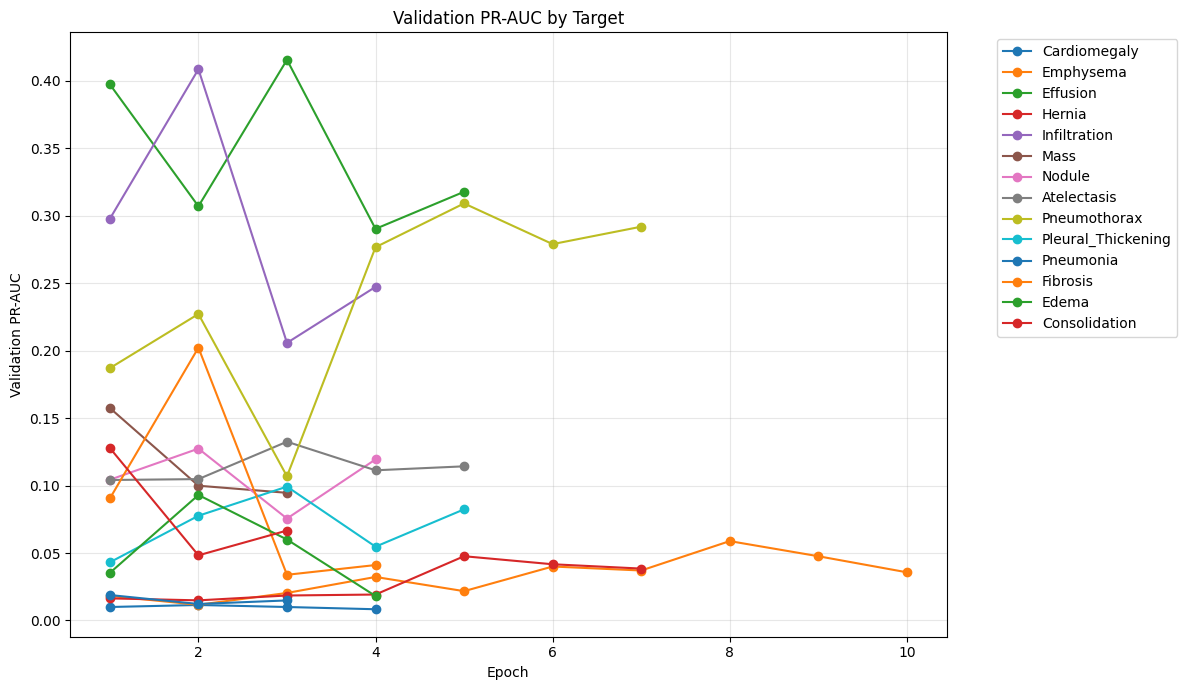

In [37]:
plt.figure(figsize=(12, 7))

for disease in disease_names:
    history = training_histories[disease]

    epochs = range(1, len(history["valid_pr_auc"]) + 1)

    plt.plot(
        epochs,
        history["valid_pr_auc"],
        marker="o",
        label=disease,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation PR-AUC")
plt.title("Validation PR-AUC by Target")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Final test evaluation

At this point, the model epoch and classification threshold for every pathology have already been selected using validation data. We now load each saved checkpoint and evaluate it **once** on the untouched test set.

In [19]:
def evaluate_saved_target_on_test(target_name):
    _, _, test_loader = make_loaders_for_target(
        target_name,
        seed=SEED,
    )

    checkpoint_path = CHECKPOINT_DIR / f"densenet121_{target_name}.pth"

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model = build_single_target_model(seed=SEED)
    model.load_state_dict(checkpoint["model_state_dict"])

    y_test, p_test = get_binary_predictions(
        model,
        test_loader,
        device,
    )

    threshold = float(checkpoint["validation_threshold"])

    metrics_default = binary_metrics(
        y_test,
        p_test,
        threshold=0.5,
    )

    metrics_tuned = binary_metrics(
        y_test,
        p_test,
        threshold=threshold,
    )

    row = {
        "Disease": target_name,
        "Best_Epoch": checkpoint["best_epoch"],
        "Validation_Threshold": threshold,
        "ROC_AUC": metrics_tuned["ROC_AUC"],
        "PR_AUC": metrics_tuned["PR_AUC"],
        "F1_Default": metrics_default["F1"],
        "F1_Tuned": metrics_tuned["F1"],
        "Sensitivity_Default": metrics_default["Sensitivity"],
        "Sensitivity_Tuned": metrics_tuned["Sensitivity"],
        "Specificity_Default": metrics_default["Specificity"],
        "Specificity_Tuned": metrics_tuned["Specificity"],
        "Test_Pos": metrics_tuned["N_Pos"],
        "Test_Neg": metrics_tuned["N_Neg"],
    }

    del model, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return row

In [43]:
test_rows = []

for disease in disease_names:
    print(f"Testing: {disease}")
    test_rows.append(
        evaluate_saved_target_on_test(disease)
    )

test_results = pd.DataFrame(test_rows)
test_results

Testing: Cardiomegaly
Testing: Emphysema
Testing: Effusion
Testing: Hernia
Testing: Infiltration
Testing: Mass
Testing: Nodule
Testing: Atelectasis
Testing: Pneumothorax
Testing: Pleural_Thickening
Testing: Pneumonia
Testing: Fibrosis
Testing: Edema
Testing: Consolidation


,Disease,Best_Epoch,Validation_Threshold,ROC_AUC,PR_AUC,F1_Default,F1_Tuned,Sensitivity_Default,Sensitivity_Tuned,Specificity_Default,Specificity_Tuned,Test_Pos,Test_Neg
0,Cardiomegaly,2,0.02,0.479838,0.123125,0.000000,0.184300,0.000000,0.540000,1.000000,0.416216,50,370
1,Emphysema,8,0.01,0.661401,0.237506,0.000000,0.065574,0.000000,0.035714,1.000000,0.991758,56,364
2,Effusion,3,0.08,0.665261,0.227155,0.274510,0.271493,0.264151,0.566038,0.904632,0.623978,53,367
3,Hernia,5,0.01,0.594216,0.197421,0.000000,0.074074,0.000000,0.040000,1.000000,0.994595,50,370
4,Infiltration,2,0.13,0.588384,0.203145,0.121951,0.260870,0.084746,0.457627,0.950139,0.664820,59,361
5,Mass,1,0.11,0.673889,0.231031,0.000000,0.100000,0.000000,0.066667,1.000000,0.955556,60,360
6,Nodule,2,0.10,0.527272,0.133878,0.000000,0.106195,0.000000,0.111111,1.000000,0.855191,54,366
7,Atelectasis,3,0.05,0.607269,0.219881,0.164706,0.278027,0.116667,0.516667,0.950000,0.633333,60,360
8,Pneumothorax,5,0.14,0.609813,0.225542,0.000000,0.151515,0.000000,0.090909,0.997260,0.983562,55,365
9,Pleural_Thickening,3,0.05,0.510526,0.153914,0.000000,0.089888,0.000000,0.068966,1.000000,0.925414,58,362


In [44]:
test_results.to_csv(
    "single_target_test_results.csv",
    index=False,
)

print("Saved single_target_test_results.csv")

Saved single_target_test_results.csv


## 9. Aggregate summary

ROC-AUC and PR-AUC are threshold-independent. F1, sensitivity, and specificity are shown both at the default threshold of 0.5 and at the pathology-specific threshold chosen on validation data.

In [45]:
summary = pd.DataFrame({
    "Model": ["14 independent single-target DenseNet121 models"],
    "Macro ROC-AUC": [np.nanmean(test_results["ROC_AUC"])],
    "Macro PR-AUC": [np.nanmean(test_results["PR_AUC"])],
    "Mean F1 Default": [np.nanmean(test_results["F1_Default"])],
    "Mean F1 Tuned": [np.nanmean(test_results["F1_Tuned"])],
    "Mean Sensitivity Default": [np.nanmean(test_results["Sensitivity_Default"])],
    "Mean Sensitivity Tuned": [np.nanmean(test_results["Sensitivity_Tuned"])],
    "Mean Specificity Default": [np.nanmean(test_results["Specificity_Default"])],
    "Mean Specificity Tuned": [np.nanmean(test_results["Specificity_Tuned"])],
})

summary

,Model,Macro ROC-AUC,Macro PR-AUC,Mean F1 Default,Mean F1 Tuned,Mean Sensitivity Default,Mean Sensitivity Tuned,Mean Specificity Default,Mean Specificity Tuned
0,14 independent single-target DenseNet121 models,0.597252,0.200315,0.045474,0.177797,0.036112,0.266791,0.985666,0.804796


## 10. Recommended comparison with the multi-label model

The scientifically clean comparison is now:

1. **Multi-label model:** one ImageNet-pretrained DenseNet121 with 14 outputs.
2. **Single-target models:** 14 independent ImageNet-pretrained DenseNet121 models with one output each.

Keep the following choices aligned between the two experiments whenever possible:

- the exact patient-level train/validation/test split;
- preprocessing;
- pretrained backbone;
- unweighted BCE loss;
- optimizer and learning rate;
- maximum training budget;
- validation-only checkpoint/threshold selection;
- final evaluation on the untouched test set.

Then compare **per-pathology ROC-AUC and PR-AUC first**, followed by threshold-dependent F1, sensitivity, and specificity. This directly tests whether joint multi-label learning helps or hurts each pathology relative to an independently trained classifier.

In [20]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)

all_results = {}

for disease in disease_names:

    print(f"Evaluating {disease}...")

    # Test loader already defined by the notebook
    _, _, test_loader = make_loaders_for_target(
        disease,
        seed=SEED,
    )

    # Load saved checkpoint
    checkpoint_path = (
        CHECKPOINT_DIR / f"densenet121_{disease}.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    # Rebuild architecture and load saved weights
    model = build_single_target_model(seed=SEED)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    # Predictions
    y_true, y_prob = get_binary_predictions(
        model,
        test_loader,
        device,
    )

    all_results[disease] = {
        "y_true": y_true,
        "y_prob": y_prob,
    }

Evaluating Cardiomegaly...
Evaluating Emphysema...
Evaluating Effusion...
Evaluating Hernia...
Evaluating Infiltration...
Evaluating Mass...
Evaluating Nodule...
Evaluating Atelectasis...
Evaluating Pneumothorax...
Evaluating Pleural_Thickening...
Evaluating Pneumonia...
Evaluating Fibrosis...
Evaluating Edema...
Evaluating Consolidation...


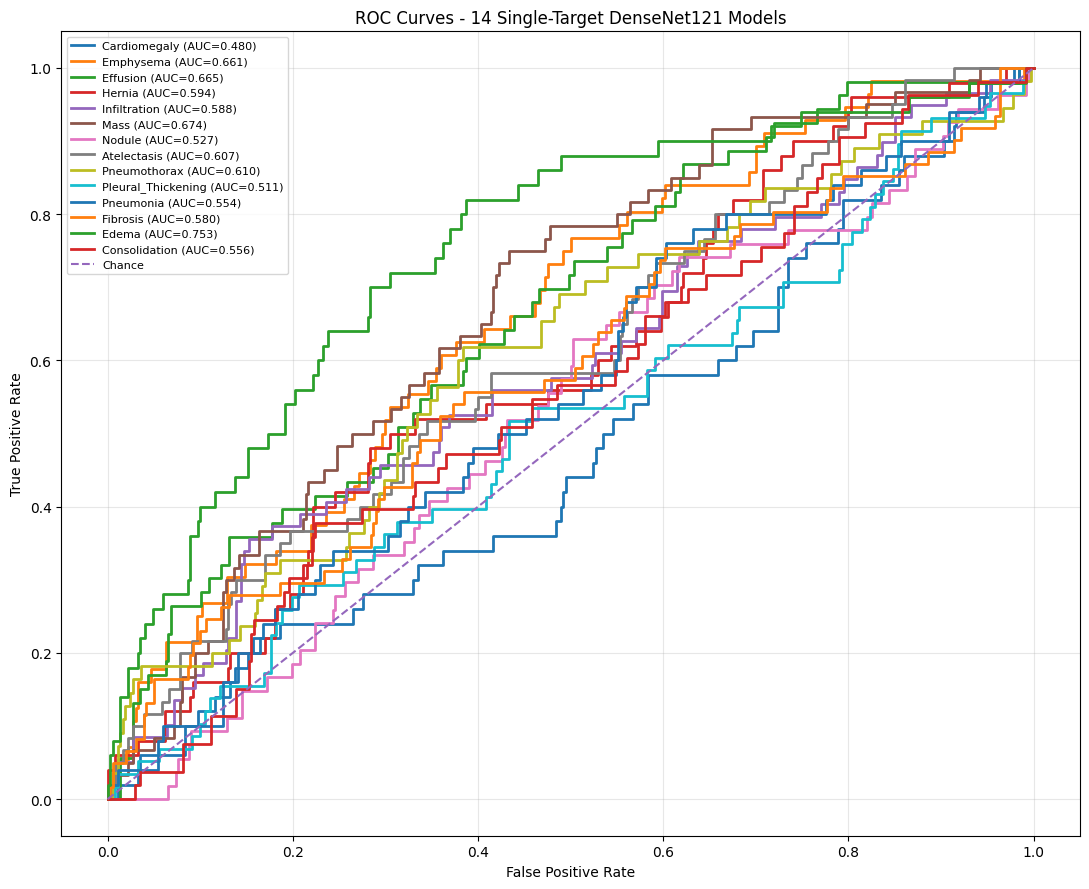

In [21]:
plt.figure(figsize=(11, 9))

for disease in disease_names:

    y_true = all_results[disease]["y_true"]
    y_prob = all_results[disease]["y_prob"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)

    roc_auc = roc_auc_score(
        y_true,
        y_prob,
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{disease} (AUC={roc_auc:.3f})",
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Chance",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - 14 Single-Target DenseNet121 Models")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

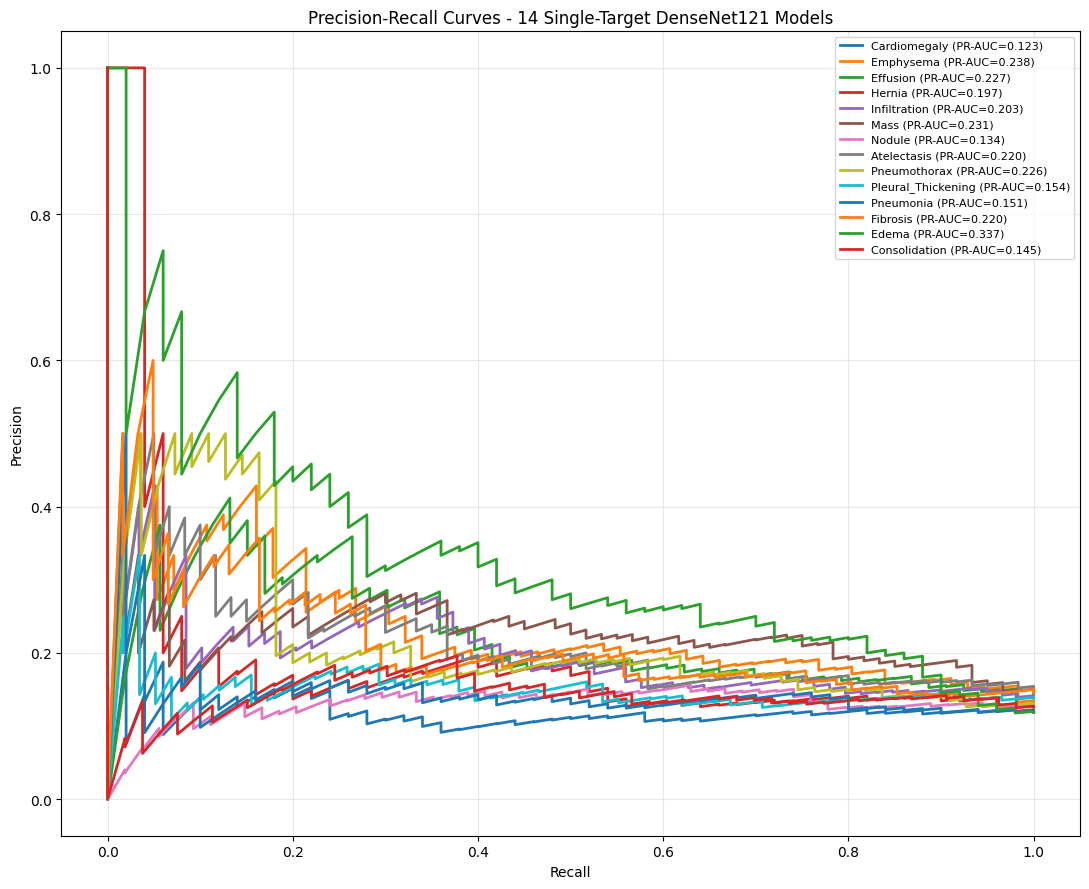

In [22]:
plt.figure(figsize=(11, 9))

for disease in disease_names:

    y_true = all_results[disease]["y_true"]
    y_prob = all_results[disease]["y_prob"]

    precision, recall, _ = precision_recall_curve(
        y_true,
        y_prob,
    )

    pr_auc = average_precision_score(
        y_true,
        y_prob,
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{disease} (PR-AUC={pr_auc:.3f})",
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "Precision-Recall Curves - 14 Single-Target DenseNet121 Models"
)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()